* DSC640-T302 Data Presentation & Visualization (2267-1)
* Term Project: Milestone 1
* David Jorgensen

# The Second Rent: What a Decade of Childcare Prices Reveals About American Affordability
**Term Project EDA**

**Dataset:** National Database of Childcare Prices (NDCP), U.S. Department of Labor, Women's Bureau
**Coverage:** 3,144 counties × 11 years (2008–2018) × 227 fields

This notebook profiles the NDCP, verifies what each field means against the technical guide, and builds toward a single story: *for families with young children, childcare has become a second rent, and infant care is where the budget breaks.*


## 1. Load and profile the data

The file is a single sheet. Each row is one **county-year**. Fields fall into four families:

- **Geography / year:** `State_Name`, `County_Name`, `County_FIPS_Code`, `StudyYear`
- **Labor & income context:** unemployment (`UNR_*`), female labor-force participation (`FLFPR_*`), median household income (`MHI`, and inflation-adjusted `MHI_2018`)
- **Demographics:** population, race, household composition (`H_Under6_*`, etc.)
- **Childcare prices:** **weekly, full-time** median (`M`) and 75th-percentile (`_75`) prices, split by **setting** (center-based `C` vs. family childcare `FCC`) and by **age** (`Infant`, `Toddler`, `Preschool`, plus fine-grained month bands).


In [ ]:
# Load libraries
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

# Set plot style
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

# Load the childcare price dataset and print basic info
df = pd.read_excel('data/nationaldatabaseofchildcareprices.xlsx')
print('Shape:', df.shape)
print('Years:', df.StudyYear.min(), '–', df.StudyYear.max())
print('Counties (FIPS):', df.County_FIPS_Code.nunique())
print('States + DC:', df.State_Name.nunique())
df[['State_Name','County_Name','StudyYear','MCInfant','MCPreschool','MFCCInfant','MHI']].head()

Shape: (34567, 227)
Years: 2008 – 2018
Counties (FIPS): 3144
States + DC: 51


,State_Name,County_Name,StudyYear,MCInfant,MCPreschool,MFCCInfant,MHI
0,Alabama,Autauga County,2008,104.95,85.92,83.45,50837.0
1,Alabama,Autauga County,2009,105.11,87.59,87.39,51463.0
2,Alabama,Autauga County,2010,105.28,89.26,91.33,53255.0
3,Alabama,Autauga County,2011,105.45,90.93,95.28,53899.0
4,Alabama,Autauga County,2012,105.61,92.60,99.22,53773.0


### Field key for the columns we rely on

| Column | Meaning |
|---|---|
| `MCInfant` / `MCToddler` / `MCPreschool` | Median **weekly** price, **center-based** care, by age |
| `MFCCInfant` / `MFCCToddler` / `MFCCPreschool` | Median **weekly** price, **family childcare** home, by age |
| `_75CInfant` … | 75th-percentile (higher-end) center price |
| `MHI` / `MHI_2018` | Median household income (nominal / in constant 2018 dollars) |
| `FLFPR_20to64_Under6` | Female labor-force participation rate, women 20–64 with children under 6 |

Prices are full-time weekly rates; we annualize with ×52 where useful.


In [ ]:
# Missingness on the key price fields
price_cols = ['MCInfant','MCToddler','MCPreschool','MFCCInfant','MFCCToddler','MFCCPreschool']
# Calculate and print % missing for each price field, and count of missing MHI values
miss = df[price_cols].isna().mean().mul(100).round(1)
print('% missing by price field:')
print(miss)
print()
print('MHI missing:', df.MHI.isna().sum(), '(income is fully populated)')

% missing by price field:
MCInfant         31.7
MCToddler        31.7
MCPreschool      31.7
MFCCInfant       32.4
MFCCToddler      32.4
MFCCPreschool    32.4
dtype: float64

MHI missing: 0 (income is fully populated)


**Data-quality note.** Roughly a third of county-years lack a published price (small or rural counties where survey samples were too thin). Income and demographics are complete. We restrict price analyses to rows where the relevant price exists, and we keep that selection bias in mind: counties that *report* prices skew more populous.


## 2. The headline: childcare as a share of income

The federal benchmark for "affordable" childcare (U.S. Dept. of Health & Human Services) is **7% of household income**. We compare annualized center-based infant care against median household income for every county-year.


In [ ]:
# Drop rows with missing infant care price or MHI
d = df.dropna(subset=['MCInfant','MHI']).copy()
# Calculate annual infant care cost and its share of median household income
d['annual_infant'] = d['MCInfant'] * 52
d['infant_share']  = d['annual_infant'] / d['MHI'] * 100

# Summary stats and share of county-years above common affordability benchmarks
print('Center infant care as % of median household income (n={:,} county-years):'.format(len(d)))
print(d['infant_share'].describe().round(1))
print()
for thr in (7,10,15):
    print(f'Counties above {thr}% of income: {(d.infant_share>thr).mean()*100:.1f}%')

Center infant care as % of median household income (n=23,593 county-years):
count    23593.0
mean        16.4
std          4.6
min          3.3
25%         13.3
50%         15.9
75%         18.6
max         54.3
Name: infant_share, dtype: float64

Counties above 7% of income: 99.9%
Counties above 10% of income: 95.9%
Counties above 15% of income: 59.3%


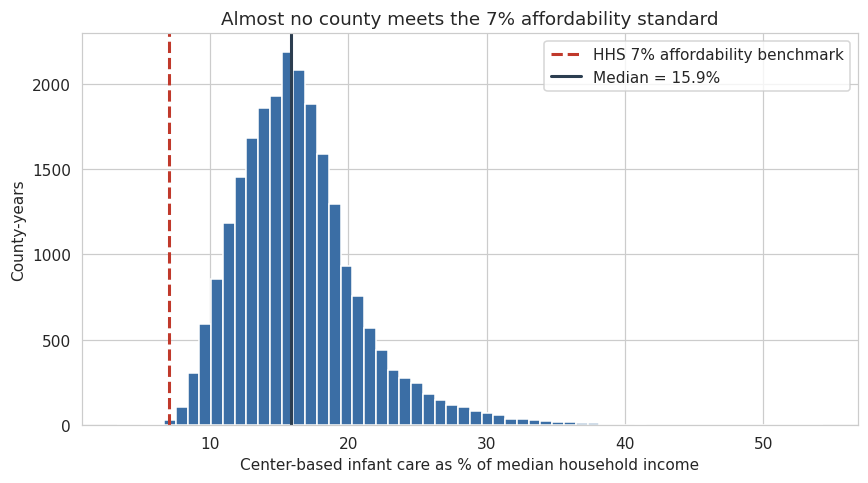

In [ ]:
# Distribution plot
fig, ax = plt.subplots(figsize=(8,4.5))
# Plot histogram of infant care share of income
ax.hist(d['infant_share'], bins=60, color='#3b6ea5', edgecolor='white')
# Add vertical lines for 7% benchmark and median
ax.axvline(7, color='#c0392b', lw=2, ls='--', label='HHS 7% affordability benchmark')
ax.axvline(d['infant_share'].median(), color='#2c3e50', lw=2, label=f'Median = {d.infant_share.median():.1f}%')
ax.set_xlabel('Center-based infant care as % of median household income')
ax.set_ylabel('County-years')
ax.set_title('Almost no county meets the 7% affordability standard')
ax.legend()
plt.tight_layout(); plt.show()

The 7% line sits far to the left of the entire distribution. The typical county spends roughly **16%** of median household income on a single infant in center care, which is more than double the federal definition of affordable. This is the spine of the story.


## 3. Two premiums: age and setting

Within the price data, two structural gaps stand out.


In [ ]:
# Compare median prices for infant vs preschool care
# Drop rows with missing infant or preschool care price
g = df.dropna(subset=['MCInfant','MCPreschool'])
# Calculate infant care premium over preschool as a percentage
age_prem = (g.MCInfant.median()/g.MCPreschool.median()-1)*100
print(f'Median infant ${g.MCInfant.median():.0f}/wk vs preschool ${g.MCPreschool.median():.0f}/wk  ->  infant premium {age_prem:.0f}%')

# Compare median prices for center-based vs family childcare for infants
# Drop rows with missing center-based or family childcare infant care price
s = df.dropna(subset=['MCInfant','MFCCInfant'])
# Calculate center-based infant care premium over family childcare as a percentage
set_prem = (s.MCInfant.median()/s.MFCCInfant.median()-1)*100
print(f'Center ${s.MCInfant.median():.0f}/wk vs family childcare ${s.MFCCInfant.median():.0f}/wk  ->  center premium {set_prem:.0f}%')

Median infant $134/wk vs preschool $114/wk  ->  infant premium 18%
Center $134/wk vs family childcare $106/wk  ->  center premium 26%


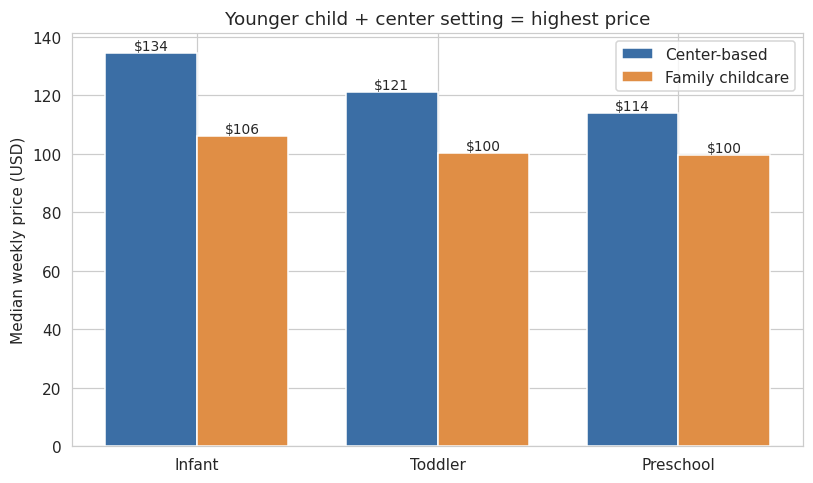

In [ ]:
# Grouped bars: price by age x setting (medians)
# Note: this is a bit rough since we have different missingness patterns
# across the 6 price fields, but it gives a nice visual of the general
# pattern that infant care is more expensive than toddler/preschool,
# and center-based care is more expensive than family childcare.

# Calculate medians for each age and setting
ages = ['Infant','Toddler','Preschool']
center = [df['MC'+a].median() for a in ages]
family = [df['MFCC'+a].median() for a in ages]
# Create grouped bar chart
x = np.arange(len(ages)); w=0.38
fig, ax = plt.subplots(figsize=(7.5,4.5))
ax.bar(x-w/2, center, w, label='Center-based', color='#3b6ea5')
ax.bar(x+w/2, family, w, label='Family childcare', color='#e08e45')
# Add labels on top of bars
for i,(cc,ff) in enumerate(zip(center,family)):
    ax.text(i-w/2, cc+1, f'${cc:.0f}', ha='center', fontsize=9)
    ax.text(i+w/2, ff+1, f'${ff:.0f}', ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(ages)
ax.set_ylabel('Median weekly price (USD)')
ax.set_title('Younger child + center setting = highest price')
ax.legend()
plt.tight_layout(); plt.show()

Infant care runs **~18% above** preschool, and a center costs **~26% more** than a family childcare home. The cruelty of the timing: infant care lands exactly when a household is youngest, often on one reduced income after a parental leave.


## 4. The decade trend (real vs. nominal)

Nominal prices always rise. The real question is whether childcare outpaced general inflation. We deflate the 2008 median infant price to 2018 dollars using CPI-U annual averages (2008 = 215.303, 2018 = 251.107).


2008 median: $121/wk  (= $141 in 2018$)
2018 median: $154/wk
Nominal growth: 27.3%   |   Real growth: 9.2%


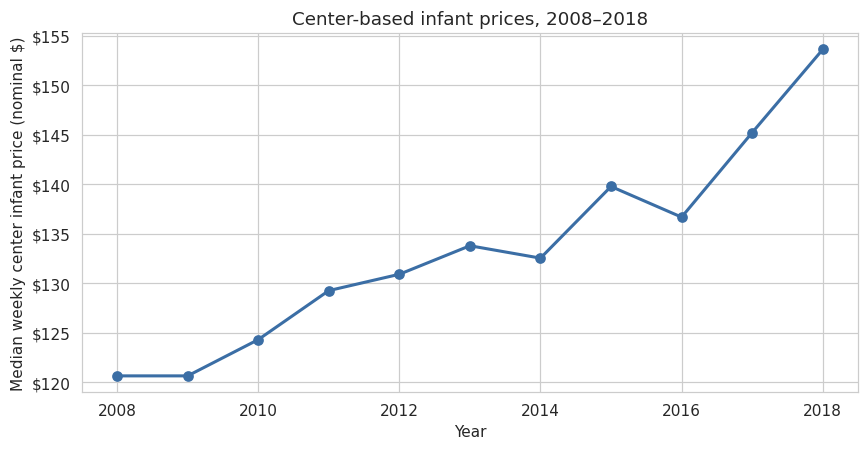

In [ ]:
# Price trends over time for center-based infant care

# define CPI values for 2008 and 2018 to adjust for inflation
cpi = {2008:215.303, 2018:251.107}
# Calculate median center-based infant care price by year
yearly = df.dropna(subset=['MCInfant']).groupby('StudyYear')['MCInfant'].median()
# Calculate real price in 2018 dollars for 2008 median price
p08, p18 = yearly.loc[2008], yearly.loc[2018]
p08_real = p08 * cpi[2018]/cpi[2008]
print(f'2008 median: ${p08:.0f}/wk  (= ${p08_real:.0f} in 2018$)')
print(f'2018 median: ${p18:.0f}/wk')
print(f'Nominal growth: {(p18/p08-1)*100:.1f}%   |   Real growth: {(p18/p08_real-1)*100:.1f}%')

# Plot price trends over time for center-based infant care
fig, ax = plt.subplots(figsize=(8,4.2))
ax.plot(yearly.index, yearly.values, marker='o', color='#3b6ea5', lw=2)
ax.set_xlabel('Year'); ax.set_ylabel('Median weekly center infant price (nominal $)')
ax.set_title('Center-based infant prices, 2008–2018')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('${x:.0f}'))
plt.tight_layout(); plt.show()

Even after inflation, infant care got **~9% more expensive in real terms** across the decade, which demonstrates a steady climb through both recession and recovery.


## 5. Geography: where the burden lands hardest

We rank states by the median county's infant-care share of income in 2018.


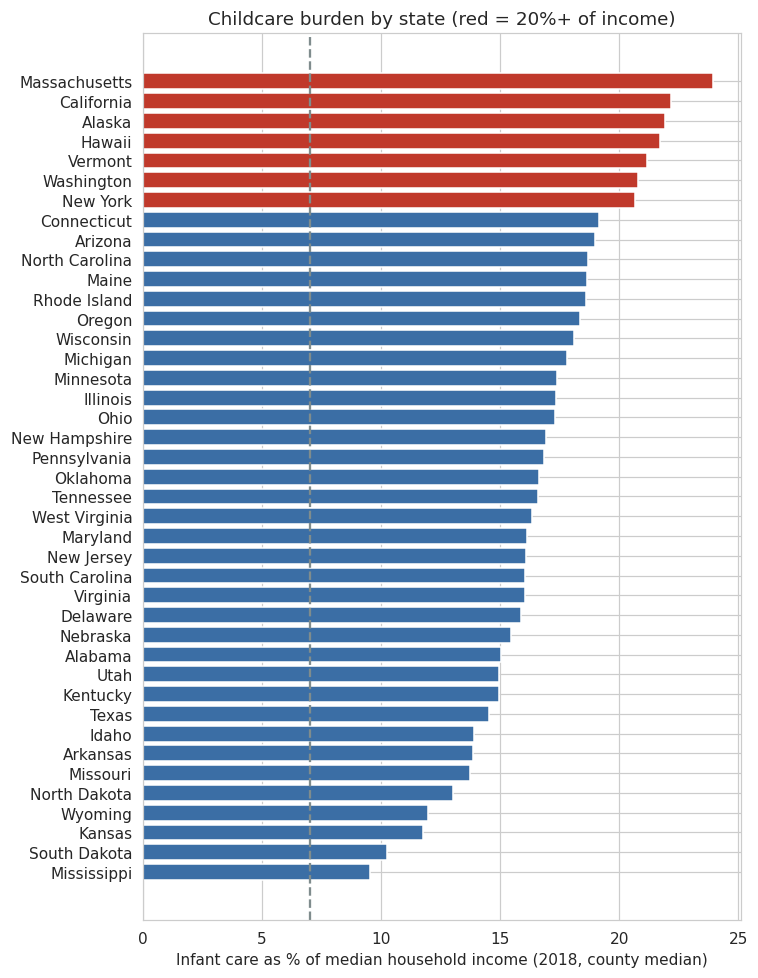

Least affordable:
State_Name
Massachusetts    23.9
California       22.2
Alaska           21.9
Hawaii           21.7
Vermont          21.2
Name: share, dtype: float64

Most "affordable":
State_Name
Mississippi      9.5
South Dakota    10.2
Kansas          11.8
Wyoming         12.0
North Dakota    13.0
Name: share, dtype: float64


In [ ]:
# State-level affordability: infant care as % of median household income

# For the most recent year (2018), drop rows with missing infant care price or MHI
d18 = df[df.StudyYear==2018].dropna(subset=['MCInfant','MHI']).copy()
# Calculate infant care cost as a share of median household income
d18['share'] = d18.MCInfant*52/d18.MHI*100
# Calculate median share by state and sort
st = d18.groupby('State_Name')['share'].median().sort_values()

# Plot state-level affordability with bars colored by whether they exceed the 7% benchmark
fig, ax = plt.subplots(figsize=(7,9))
colors = ['#c0392b' if v>=20 else '#3b6ea5' for v in st.values]
ax.barh(st.index, st.values, color=colors)
ax.axvline(7, color='#7f8c8d', ls='--', lw=1.5)
ax.set_xlabel('Infant care as % of median household income (2018, county median)')
ax.set_title('Childcare burden by state (red = 20%+ of income)')
plt.tight_layout(); plt.show()

# Print 5 least and most "affordable" states based on the median share of income spent on infant care
print('Least affordable:'); print(st.tail(5).round(1)[::-1])
print('\nMost "affordable":'); print(st.head(5).round(1))

Massachusetts, California, Alaska, Hawaii and Vermont push past **21%** of median income for one infant. The "affordable" end (Mississippi, South Dakota, Kansas) is a trap: prices look low because *incomes* are low. Cheap and affordable are not the same thing, and that distinction is something the story has to make explicit.


## 6. A caution on the labor-force angle

It is tempting to claim "expensive childcare pushes mothers out of work." The raw data does not support a clean version of that.


In [ ]:
# Correlation between infant care price

# Drop rows with missing infant care price
c = df.dropna(subset=['MCInfant','FLFPR_20to64_Under6'])
# Calculate correlation between weekly infant care price and female labor force participation
r = c['MCInfant'].corr(c['FLFPR_20to64_Under6'])
print(f'Raw correlation, weekly infant price vs female LFP (kids under 6): {r:.3f}')
print('Near zero — and confounded: high-price metros also have high incomes and high female LFP.')

Raw correlation, weekly infant price vs female LFP (kids under 6): 0.096
Near zero — and confounded: high-price metros also have high incomes and high female LFP.


The correlation is essentially flat and badly confounded (expensive metros also have high incomes and high participation). So this analysis stays disciplined: it argues **affordability**, not a causal labor-supply claim. That honesty is itself part of the message.


## 7. What the analysis establishes

1. **Childcare fails the federal affordability test almost everywhere.** ~16% of median income for infant care, vs. a 7% benchmark; 99.9% of reporting counties exceed it.
2. **The infant + center combination is the price peak** (~18% age premium, ~26% setting premium), arriving at the family's most financially fragile moment.
3. **Costs rose ~9% in real terms** over 2008–2018, which demonstrates a structural climb rather than noise.
4. **Geography reshuffles the pain**, and "cheap" states are often just low-income states.

The honest limit: about a third of counties don't report prices, and price–labor relationships are confounded. The story is about the size and shape of the burden, not a causal model of who it forces out of work.
